<a href="https://colab.research.google.com/github/rushmilak/mmck_queue_simulation/blob/main/M_M_c_K_Simulation_and_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **M/M/C/K Queue Simulation**

In [129]:
# Parameters :
lambda_AR = 9     # arrival rate
mu_SR = 10        # service rate
c = 5             # number of servers
K = 20            # system capacity == receiving service + waiting


In [130]:
import heapq
import itertools
import math
import random
import pandas as pd
from collections import deque

import numpy as np
import matplotlib.pyplot as plt

In [131]:
class Queue:
  def __init__(self, lambda_AR, mu_SR, C, K):
    self.lambda_AR = lambda_AR
    self.mu_SR = mu_SR
    self.C = C
    self.K = K
    assert C <= K

  # --------------------------------------------------------------
  def simulate(self, T_end, seed=42):
    lambda_AR, mu_SR, C, K = self.lambda_AR, self.mu_SR, self.C, self.K

    seq = itertools.count()
    rand = random.Random(seed)              # ONE generator for the whole run

    clock = 0.0
    n = 0                                   # people in system
    customer_data = []
    waiting = deque()
    events = []
    total_arrivals = blocked_arrivals = completed_services = 0
    free_servers = list(range(C))
    heapq.heapify(free_servers)

    n_vals, n_times = [0], [0.0]

    wait_total = 0.0
    served_started = 0

    last_t = 0.0
    area_n = 0.0
    area_busy = 0.0
    time_in_state = [0.0] * (K + 1)

    def push_event(time, event_type, customer_id=None):
      heapq.heappush(events, (time, next(seq), event_type, customer_id))

    push_event(rand.expovariate(lambda_AR), "arrival")

    def start_service(cid, t):
      nonlocal wait_total, served_started
      srv = heapq.heappop(free_servers)
      cu = customer_data[cid]
      cu["service_start"] = t
      cu["server"] = srv
      cu["departure_time"] = t + rand.expovariate(mu_SR)
      wait_total += t - cu["arrival_time"]
      served_started += 1
      push_event(cu["departure_time"], "departure", cid)

    while events:
      p_time, _, event_type, customer_id = heapq.heappop(events)

      if p_time > T_end:
        break

      dt = p_time - last_t
      area_n += n * dt
      area_busy += min(n, C) * dt
      time_in_state[n] += dt
      clock = last_t = p_time

      if event_type == "arrival":
        push_event(clock + rand.expovariate(lambda_AR), "arrival")
        total_arrivals += 1

        cu = {"id": len(customer_data), "arrival_time": clock,
              "service_start": math.inf, "departure_time": math.inf,
              "server": None, "blocked": False}
        customer_data.append(cu)

        if n == K:
          cu["blocked"] = True
          blocked_arrivals += 1
        else:
          n += 1
          if len(free_servers) > 0:
            start_service(cu["id"], clock)
          else:
            waiting.append(cu["id"])

      else:  # departure
        completed_services += 1
        n -= 1
        heapq.heappush(free_servers, customer_data[customer_id]["server"])
        if waiting:
          start_service(waiting.popleft(), clock)

      n_times.append(clock)
      n_vals.append(n)

    # close the final interval
    dt = T_end - last_t
    area_n += n * dt
    area_busy += min(n, C) * dt
    time_in_state[n] += dt
    n_times.append(T_end)
    n_vals.append(n)

    queue_info = {
      "total_arrivals": total_arrivals,
      "total_blocked": blocked_arrivals,
      "completed_services": completed_services,
      "total_wait_time": wait_total,
      "throughput": completed_services / T_end,
      "prob_state_n": [x / T_end for x in time_in_state],
      "block_prob": blocked_arrivals / total_arrivals if total_arrivals else 0.0,
      "average_n": area_n / T_end,
      "average_wait_time_per_customer": wait_total / served_started if served_started else 0.0,
      "capacity_utilization": area_busy / T_end / C,
    }
    return customer_data, np.array(n_times), np.array(n_vals), queue_info

  # --------------------------------------------------------------
  def analytical_soln(self):
    lambda_AR, mu_SR, C, K = self.lambda_AR, self.mu_SR, self.C, self.K
    r = lambda_AR / mu_SR                      # offered load

    probs = []
    for n in range(K + 1):
      if n < C:
        probs.append(r ** n / math.factorial(n))
      else:
        probs.append(r ** n / (math.factorial(C) * C ** (n - C)))

    total = sum(probs)
    p = [x / total for x in probs]

    L = sum(n * pn for n, pn in enumerate(p))                      # mean number in system
    effective_lambda = lambda_AR * (1 - p[K])                      # effective arrival rate
    Lq = sum((n - C) * p[n] for n in range(C + 1, K + 1))          # mean number in queue
    Wq = Lq / effective_lambda                                     # mean wait in queue
    W = L / effective_lambda                                       # mean time in system

    return {
      "block_prob": p[K],
      "capacity_utilization": effective_lambda / (C * mu_SR),
      "throughput": effective_lambda,
      "mean_n": L,
      "mean_wait": Wq,
      "mean_sys_time": W,
      "prob_state_n": p,
    }

##***Validation and Visualization***

In [132]:
# settings:
lam, mu = 45, 10
n_servers, capacity = 5, 10

# return values
q = Queue(lam, mu, n_servers, capacity)
customer_data, n_times, n_vals, info = q.simulate(T_end=2000, seed=42)
theory = q.analytical_soln()


print("customers simulated:", info["total_arrivals"], "| blocked:", info["total_blocked"])


customers simulated: 89871 | blocked: 6942


Simulation vs. Analytical

In [133]:
import pandas as pd


data = {
    "Metric": [
        "Blocking probability",
        "Utilization",
        "Throughput",
        "Mean number in system",
        "Mean wait in queue"
    ],
    "Simulation": [
        info["block_prob"],
        info["capacity_utilization"],
        info["throughput"],
        info["average_n"],
        info["average_wait_time_per_customer"]
    ],
    "Analytical": [
        theory["block_prob"],
        theory["capacity_utilization"],
        theory["throughput"],
        theory["mean_n"],
        theory["mean_wait"]
    ]
}

df = pd.DataFrame(data)
df["Difference"] = df["Simulation"] - df["Analytical"]

df

,Metric,Simulation,Analytical,Difference
0,Blocking probability,0.077244,0.075699,0.001545
1,Utilization,0.828452,0.831871,-0.003419
2,Throughput,41.460000,41.593528,-0.133528
3,Mean number in system,5.469275,5.477717,-0.008442
4,Mean wait in queue,0.032001,0.031696,0.000305


P(n) of analytical vs. simulation -- Customers in the system

<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

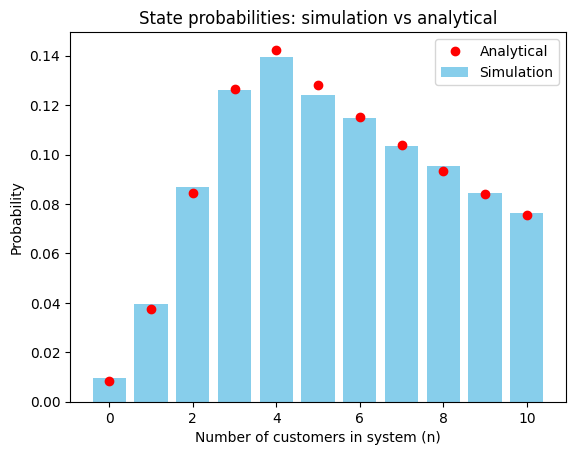

In [134]:
states = np.arange(capacity + 1)

plt.figure()

plt.bar(states, info["prob_state_n"], color="skyblue", label="Simulation")
plt.plot(states, theory["prob_state_n"],  "ro" , label="Analytical")

plt.xlabel("Number of customers in system (n)")
plt.ylabel("Probability")
plt.title("State probabilities: simulation vs analytical")

plt.legend()

plt

n(t) [number of customers in the system at time - t] over time, and running average

/tmp/ipykernel_763/3347610437.py:21: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



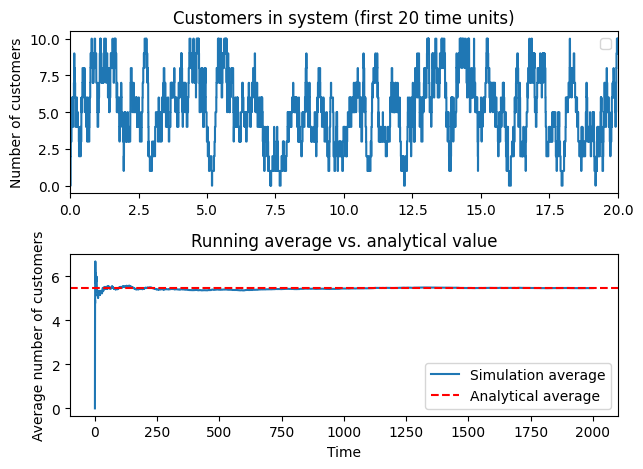

In [135]:
running_avg = []
total = 0

for i in range(1, len(n_times)):
    time_passed = n_times[i] - n_times[i - 1]
    customers = n_vals[i - 1]

    total = total + customers * time_passed
    average = total / n_times[i]

    running_avg.append(average)


fig, (top, bottom) = plt.subplots(2, 1)

# Number of customers
top.step(n_times, n_vals, where="post") # post - keep the value till next event
top.set_xlim(0, 20) # first twenty time units
top.set_ylabel("Number of customers")
top.set_title("Customers in system (first 20 time units)")
top.legend()

# Running average
bottom.plot(n_times[1:], running_avg, label="Simulation average")
bottom.axhline(theory["mean_n"], color="red", linestyle="--", label="Analytical average")
bottom.set_xlabel("Time")
bottom.set_ylabel("Average number of customers")
bottom.set_title("Running average vs. analytical value")
bottom.legend()

plt.tight_layout()
plt.show()

# NOTE that, mean number of customers: Simulation: 5.469275, Analytical: 5.477717.

Busy servers, queue length, blocked customers

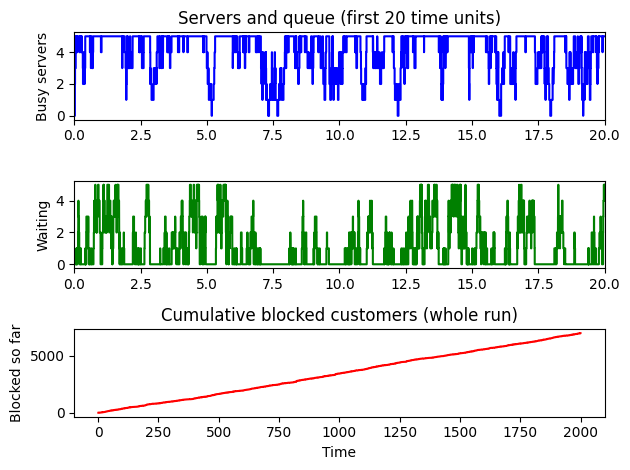

In [136]:
busy = np.minimum(n_vals, n_servers) # people being served
waiting = np.maximum(n_vals - n_servers, 0) # people waiting
blocked_times = [cu["arrival_time"] for cu in customer_data if cu["blocked"]]

fig, axes = plt.subplots(3, 1)

axes[0].step(n_times, busy, where="post", color="blue")
axes[0].set_ylabel("Busy servers")
axes[1].step(n_times, waiting, where="post", color="green")
axes[1].set_ylabel("Waiting")
for ax in axes[:2]:
    ax.set_xlim(0, 20) # 20 time units
axes[0].set_title("Servers and queue (first 20 time units)")

# blocked_times

axes[2].step(blocked_times, np.arange(1, len(blocked_times) + 1), where="post", color="red")
axes[2].set_xlabel("Time")
axes[2].set_ylabel("Blocked so far")
axes[2].set_title("Cumulative blocked customers (whole run)")

plt.tight_layout()
plt.show()

Wait Times


Fraction of served customers who had to wait: 0.5677298763943323



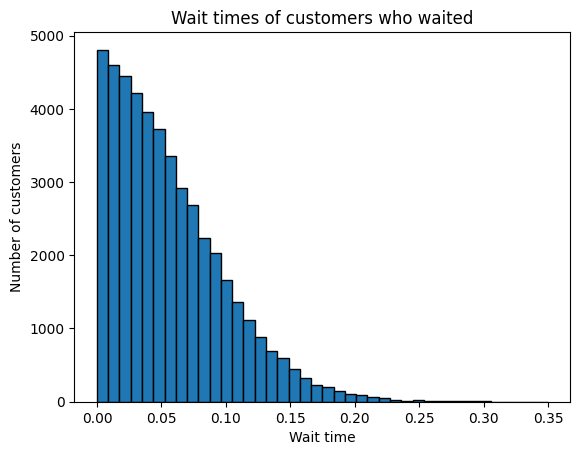

In [137]:
waits = [cu["service_start"] - cu["arrival_time"]
         for cu in customer_data
         if not cu["blocked"] and cu["service_start"] < math.inf]

had_to_wait = [w for w in waits if w > 0]

print(f"Fraction of served customers who had to wait: {len(had_to_wait) / len(waits)}")
print()

plt.figure()
plt.hist(had_to_wait, bins=40, edgecolor="black")
plt.xlabel("Wait time")
plt.ylabel("Number of customers")
plt.title("Wait times of customers who waited")
plt.show()

# NOTE: Avg. waiting time is: (simulation, analytical) = (0.032001,	0.031696)

Blocked probabilities across seeds

<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

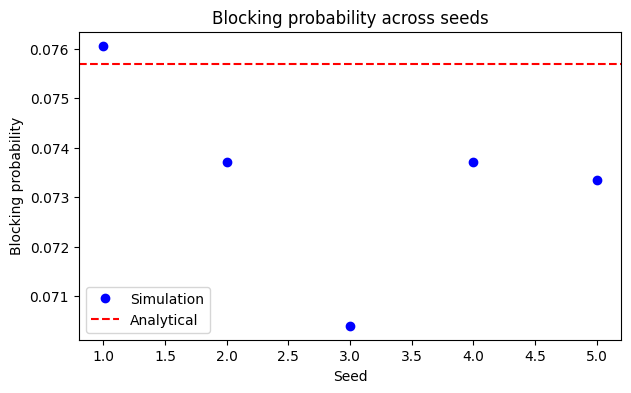

In [138]:
seeds = [1, 2, 3, 4, 5]
block_by_seed = []
for s in seeds:
    _, _, _, inf = q.simulate(T_end=1000, seed=s)
    block_by_seed.append(inf["block_prob"])

plt.figure(figsize=(7, 4))
plt.plot(seeds, block_by_seed, "bo", label="Simulation")
plt.axhline(theory["block_prob"], color="red", linestyle="--", label="Analytical")
plt.xlabel("Seed")
plt.ylabel("Blocking probability")
plt.title("Blocking probability across seeds")
plt.legend()
# block_by_seed

plt

Blocked probability vs. Arrival rate

<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

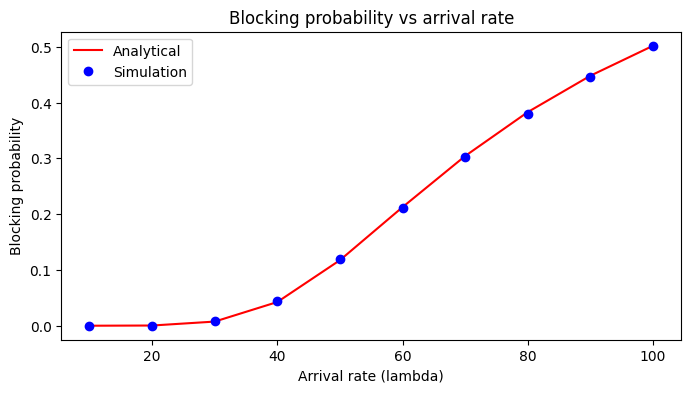

In [139]:
lams = np.arange(10, 101, 10)
sim_block, ana_block = [], []
for l in lams:
    qq = Queue(l, mu, n_servers, capacity)
    _, _, _, inf = qq.simulate(T_end=1000, seed=1)
    sim_block.append(inf["block_prob"])
    ana_block.append(qq.analytical_soln()["block_prob"])

plt.figure(figsize=(8, 4))
plt.plot(lams, ana_block, "r-", label="Analytical")
plt.plot(lams, sim_block, "bo", label="Simulation")
plt.xlabel("Arrival rate (lambda)")
plt.ylabel("Blocking probability")
plt.title("Blocking probability vs arrival rate")
plt.legend()

plt

In [140]:
%pip install plotly

**SIMULATION VISUALIZATION**

In [141]:
import numpy as np
import plotly.graph_objects as go


start_time = 20
stop_time = 25
dt = 0.05

T = np.arange(start_time, stop_time + dt/2, dt) # we take frames between 20 time to 24 time, interval: 0.05 time unit

# np.searchsorted() will return where (right) t time should be put to maintain sorted state in n_times
# then doing -1, that gives us the index of n_vals where S(t) exists
# S(t) returns # of customers in the system at t time
S = lambda t: int(n_vals[ max(0, np.searchsorted(n_times, t, side="right")-1) ])


B = np.array([c["arrival_time"] for c in customer_data if c["blocked"]]) # collecting blocked customer's arrival times

# title (t)
title = lambda t: (
    f"M/M/C/K | t={t:.2f} | n={S(t)}/{capacity} | "
    f"busy={min(S(t), n_servers)}/{n_servers} | "
    f"waiting={max(S(t)-n_servers, 0)} | "
    f"blocked={np.sum((B >= start_time) & (B <= t))}"
)

# we create a frame function
def frame(i, t):
    m = (n_times > start_time) & (n_times <= t) # we take the recorded events (masks) between 20 and t

    return go.Frame(name=str(i),
                    data=[
                          go.Scatter(x=np.r_[start_time, n_times[m], t], y=np.r_[S(start_time), n_vals[m], S(t)]), # till time t
                          go.Scatter(x=[t], y=[S(t)]) # at time t
                         ],
                    traces=[0,1],
                    layout=go.Layout(title_text=title(t)))



# now we create the animated figure:::
fig = go.Figure(data=[
                      go.Scatter(x=[start_time, start_time], y=[S(start_time),S(start_time)], mode="lines", line=dict(shape="hv",width=3), name="n(t)"),
                      go.Scatter(x=[start_time], y=[S(start_time)], mode="markers", marker_size=11, name="Current state")
                     ],
                frames=[frame(i,t) for i,t in enumerate(T)]
                )


# adding hlines for - n_servers, analytical mean (for comparison)
fig.add_hline(y=n_servers, line_dash="dot", annotation_text="All servers busy")
fig.add_hline(y=theory["mean_n"], line_dash="dash", annotation_text="Analytical mean")


fig.update_layout( # layout
    title=title(start_time),
    xaxis_title="Simulation time",
    yaxis_title="Customers in system",
    xaxis=dict(range=[start_time, stop_time], autorange=False, zeroline=False),
    yaxis=dict(range=[-0.5, capacity + 0.5], autorange=False, zeroline=False),
    updatemenus = [dict(type = "buttons", # adding play button
        buttons = [
            dict(
                args = [None, {"frame": {"duration": 200, "redraw": True},
                                "fromcurrent": True, "transition": {"duration": 0}}],
                label = "Play",
                method = "animate",

                )])]
)


fig.show()


In [142]:
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Rectangle
from IPython.display import HTML

t_start, t_stop = 20, 24                          # the time window we animate
frame_times = np.linspace(t_start, t_stop, 100)   # 100 frames

# keep only the customers that matter inside this window (keeps it fast)
people  = [cu for cu in customer_data
           if not cu["blocked"] and cu["arrival_time"] <= t_stop and cu["departure_time"] >= t_start]
rejects = [cu["arrival_time"] for cu in customer_data
           if cu["blocked"] and t_start <= cu["arrival_time"] <= t_stop]

fig, (ax_sys, ax_n) = plt.subplots(1, 2, figsize=(12, 4))

def draw_frame(i):
    t = frame_times[i]
    in_service   = [p for p in people if p["service_start"] <= t < p["departure_time"]]
    in_waiting   = [p for p in people if p["arrival_time"] <= t < p["service_start"]]
    just_blocked = [r for r in rejects if t - 0.1 <= r <= t]
    busy_ids     = {p["server"] for p in in_service}

    # ---- left panel: servers and waiting room
    ax_sys.clear()
    for s in range(n_servers):
        color = "tomato" if s in busy_ids else "lightgreen"
        ax_sys.add_patch(Rectangle((s * 1.2, 2), 1, 1, facecolor=color, edgecolor="black"))
    for j in range(capacity - n_servers):
        color = "orange" if j < len(in_waiting) else "white"
        ax_sys.add_patch(Rectangle((j * 1.2, 0), 1, 1, facecolor=color, edgecolor="black"))
    ax_sys.text(0, 3.2, "Servers", fontsize=11)
    ax_sys.text(0, 1.2, "Waiting room", fontsize=11)
    if just_blocked:
        ax_sys.text(0, -0.8, "BLOCKED!", color="red", fontsize=18, fontweight="bold")
    ax_sys.set_xlim(-0.2, max(n_servers, capacity - n_servers) * 1.2)
    ax_sys.set_ylim(-1.2, 4)
    ax_sys.axis("off")
    blocked_so_far = sum(r <= t for r in rejects)
    ax_sys.set_title(f"t = {t:.2f}   in system = {len(in_service) + len(in_waiting)}"
                     f"   blocked (this window) = {blocked_so_far}")

    # ---- right panel: n(t) drawing itself
    ax_n.clear()
    mask = (n_times >= t_start) & (n_times <= t)
    ax_n.step(n_times[mask], n_vals[mask], where="post")
    ax_n.axhline(theory["mean_n"], color="red", linestyle="--", label="Analytical L")
    ax_n.set_xlim(t_start, t_stop)
    ax_n.set_ylim(0, capacity + 1)
    ax_n.set_xlabel("Time")
    ax_n.set_ylabel("n(t)")
    ax_n.legend(loc="lower right")

anim = FuncAnimation(fig, draw_frame, frames=len(frame_times), interval=80)
plt.close(fig)                 # stop Colab from also showing a still image
HTML(anim.to_jshtml())         # shows the animation with play/pause controls
# anim.save("queue.gif", writer="pillow")   # optional: save as a GIF for your slides

# **TimeGPT**

In [143]:
pip install nixtla

In [144]:
from nixtla import NixtlaClient

client = NixtlaClient(
    api_key='nixak-6e0f0eac89bf4f74a6c6a4582a9f1e00d81e8958ba9f0217baa376459731a6e81af573d8c10d06a2'
)

In [145]:
client.validate_api_key()

True

In [146]:
step = 0.1
start = pd.Timestamp("2026-10-13 00:00:00")
unit = "sec"
ID = "mmck"
n_times = np.asarray(n_times, float)
n_vals = np.asarray(n_vals, float)
T_end = n_times[-1]
grid = np.arange(0.0, T_end + 1e-9, step)
idx = np.clip(np.searchsorted(n_times, grid, side="right") - 1, 0, len(n_vals) - 1)

t_vals, y = grid, n_vals[idx]
df = pd.DataFrame({
    "unique_id": ID,
    "ds": start + pd.to_timedelta(t_vals, unit=unit),
    "y": y,
})
print(df.shape)
print(df.head(10))
print(df["y"].describe())

(20001, 3)
  unique_id                      ds     y
0      mmck 2026-10-13 00:00:00.000   0.0
1      mmck 2026-10-13 00:00:00.100   6.0
2      mmck 2026-10-13 00:00:00.200   4.0
3      mmck 2026-10-13 00:00:00.300   4.0
4      mmck 2026-10-13 00:00:00.400   3.0
5      mmck 2026-10-13 00:00:00.500   7.0
6      mmck 2026-10-13 00:00:00.600   5.0
7      mmck 2026-10-13 00:00:00.700   3.0
8      mmck 2026-10-13 00:00:00.800   9.0
9      mmck 2026-10-13 00:00:00.900  10.0
count    20001.000000
mean         5.471726
std          2.584282
min          0.000000
25%          3.000000
50%          5.000000
75%          8.000000
max         10.000000
Name: y, dtype: float64


train: 19801 rows  (2026-10-13 00:00:00 -> 2026-10-13 00:33:00)
test : 200 rows  (2026-10-13 00:33:00.100000 -> 2026-10-13 00:33:20)
TimeGPT  MAE=2.256  RMSE=2.598
Train-mean baseline MAE=2.253


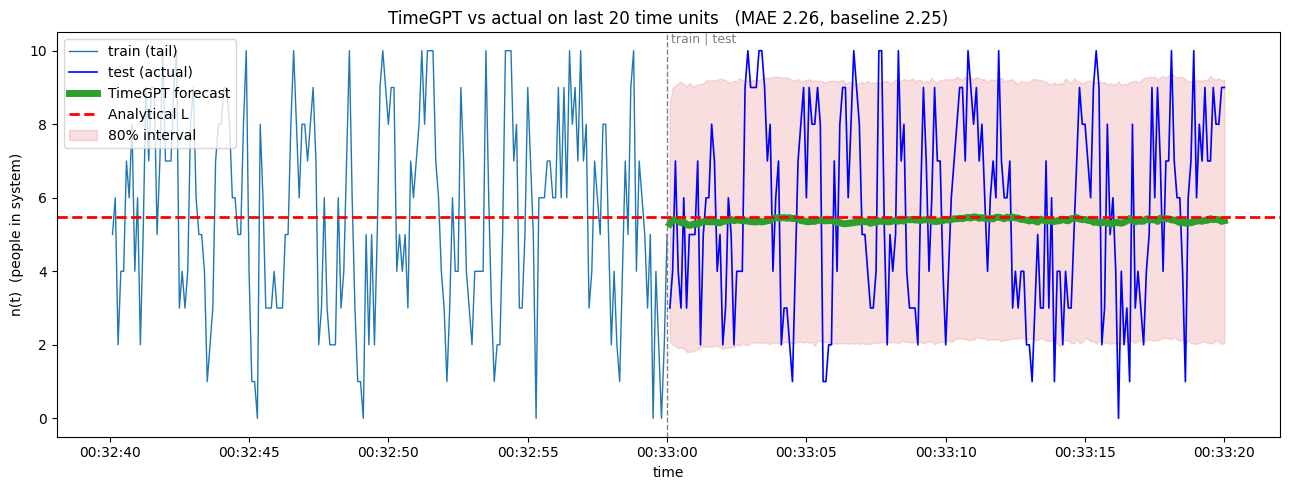

In [147]:
TEST_UNITS = 20          # last N simulation time units = test set
LEVEL = [80]              # prediction interval(s); use [] for none
CONTEXT_UNITS = 20       # how much of the training tail to show in the plot

df = df.sort_values("ds").reset_index(drop=True)
unit_td = pd.Timedelta(1, unit=unit)                    # one simulation time unit as a Timedelta
cutoff = df["ds"].max() - TEST_UNITS * unit_td          # test = everything after the cutoff

train = df[df["ds"] <= cutoff].reset_index(drop=True)
test = df[df["ds"] > cutoff].reset_index(drop=True)
print(f"train: {len(train)} rows  ({train.ds.min()} -> {train.ds.max()})")
print(f"test : {len(test)} rows  ({test.ds.min()} -> {test.ds.max()})")

# ---------------- forecast exactly the test horizon ----------------
freq = pd.infer_freq(train["ds"])
fcst = client.forecast(df=train, h=len(test), freq=freq, level=LEVEL,
                       time_col="ds", target_col="y")

# ---------------- line up forecast and test ----------------
res = test.merge(fcst, on=["unique_id", "ds"], how="left")      # columns: y, TimeGPT, (lo/hi)
mae = (res["y"] - res["TimeGPT"]).abs().mean()
rmse = np.sqrt(((res["y"] - res["TimeGPT"]) ** 2).mean())
base = train["y"].mean()                                        # naive baseline: train mean
mae_base = (res["y"] - base).abs().mean()
print(f"TimeGPT  MAE={mae:.3f}  RMSE={rmse:.3f}")
print(f"Train-mean baseline MAE={mae_base:.3f}")

# ---------------- plot ----------------
ctx = train[train["ds"] > cutoff - CONTEXT_UNITS * unit_td]
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(ctx["ds"], ctx["y"], color="tab:blue", lw=1, label="train (tail)")
ax.plot(res["ds"], res["y"], color="blue", lw=1.2, label="test (actual)")
ax.plot(res["ds"], res["TimeGPT"], color="tab:green", lw=5, label="TimeGPT forecast")
ax.axhline(theory["mean_n"], color="red", linestyle="--", linewidth=2, label="Analytical L")
for lv in LEVEL:
    lo, hi = f"TimeGPT-lo-{lv}", f"TimeGPT-hi-{lv}"
    if lo in res and hi in res:
        ax.fill_between(res["ds"], res[lo], res[hi], color="tab:red", alpha=0.15, label=f"{lv}% interval")
ax.axvline(cutoff, color="gray", ls="--", lw=1)
ax.text(cutoff, ax.get_ylim()[1], " train | test", va="top", fontsize=9, color="gray")
ax.set(xlabel="time", ylabel="n(t)  (people in system)",
       title=f"TimeGPT vs actual on last {TEST_UNITS} time units   "
             f"(MAE {mae:.2f}, baseline {mae_base:.2f})")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()